# Logistic Regression - RMSprop
dataset: Body Performance Data (kaggle)

predicting if a person has good fitness or not using logistic regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/kukuroo3/body-performance-data/bodyPerformance.csv


## Load the data

In [2]:
df = pd.read_csv('/kaggle/input/datasets/kukuroo3/body-performance-data/bodyPerformance.csv')
df.head()

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [3]:
print(df.shape)
print(df.isnull().sum().sum())   # no missing values

(13393, 12)
0


In [4]:
df['class'].value_counts()

class
C    3349
D    3349
A    3348
B    3347

## Preprocessing
the class column has 4 values (A, B, C, D) so i made it binary:
- A and B = 1 (good fitness)
- C and D = 0

also changed gender to numbers (M = 1, F = 0)

In [5]:
df['gender'] = df['gender'].map({'M': 1, 'F': 0})
df['target'] = df['class'].map({'A': 1, 'B': 1, 'C': 0, 'D': 0})

X = df.drop(['class', 'target'], axis=1).values
y = df['target'].values

print(X.shape, y.shape)
print(df['target'].value_counts())

(13393, 11) (13393,)
target
0    6698
1    6695
Name: count, dtype: int64


## Train test split + scaling

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# add column of ones for the bias
X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

print(X_train.shape, X_test.shape)

(10714, 12) (2679, 12)


## Functions
- sigmoid: 1 / (1 + e^-z)
- loss: binary cross entropy
- gradient: X.T (p - y) / m

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def compute_loss(X, y, w):
    p = sigmoid(X @ w)
    p = np.clip(p, 1e-15, 1 - 1e-15)   # so log doesnt give error
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def compute_gradient(X, y, w):
    p = sigmoid(X @ w)
    return X.T @ (p - y) / len(y)

def predict(X, w):
    return (sigmoid(X @ w) >= 0.5).astype(int)

## RMSprop
keeps a moving average of the squared gradients and divides the learning rate by it, so each weight has its own learning rate

s = beta * s + (1 - beta) * g^2

w = w - lr * g / (sqrt(s) + eps)

In [8]:
np.random.seed(42)

lr = 0.01
beta = 0.9
eps = 1e-8
epochs = 50
batch_size = 64

w = np.zeros(X_train.shape[1])
s = np.zeros(X_train.shape[1])
losses = []
m = len(y_train)

for epoch in range(epochs):
    idx = np.random.permutation(m)
    X_shuffled = X_train[idx]
    y_shuffled = y_train[idx]

    for i in range(0, m, batch_size):
        X_batch = X_shuffled[i:i+batch_size]
        y_batch = y_shuffled[i:i+batch_size]
        g = compute_gradient(X_batch, y_batch, w)

        s = beta * s + (1 - beta) * g**2
        w = w - lr * g / (np.sqrt(s) + eps)

    losses.append(compute_loss(X_train, y_train, w))
    if epoch % 10 == 0:
        print('epoch', epoch, 'loss', losses[-1])

print('final loss:', losses[-1])

epoch 0 loss 0.3976843682215879
epoch 10 loss 0.3801541877222506
epoch 20 loss 0.37954444907084534
epoch 30 loss 0.3798963952045516
epoch 40 loss 0.37991723315933534
final loss: 0.380159188503407


## Loss curve

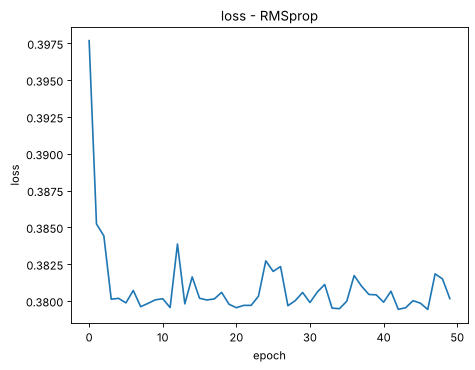

In [9]:
plt.plot(losses)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('loss - RMSprop')
plt.show()

## Evaluation

In [10]:
y_pred = predict(X_test, w)

TP = np.sum((y_pred == 1) & (y_test == 1))
TN = np.sum((y_pred == 0) & (y_test == 0))
FP = np.sum((y_pred == 1) & (y_test == 0))
FN = np.sum((y_pred == 0) & (y_test == 1))

accuracy = (TP + TN) / len(y_test)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
test_loss = compute_loss(X_test, y_test, w)

print('Accuracy :', round(accuracy, 4))
print('Precision:', round(precision, 4))
print('Recall   :', round(recall, 4))
print('F1       :', round(f1, 4))
print('Loss     :', round(test_loss, 4))

Accuracy : 0.8253
Precision: 0.8206
Recall   : 0.8352
F1       : 0.8278
Loss     : 0.3924


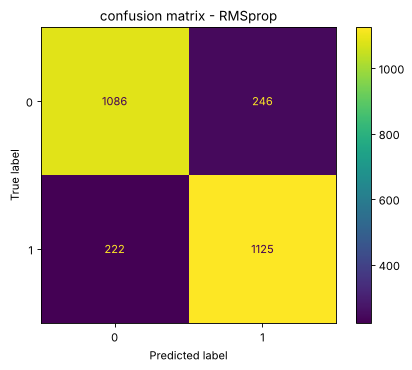

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot()
plt.title('confusion matrix - RMSprop')
plt.show()

checking my results with sklearn to make sure they are the same:

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print(accuracy_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(f1_score(y_test, y_pred))

0.8253079507278835
0.8205689277899344
0.8351893095768375
0.8278145695364238
